# Evaluación Formativa 1: caracterización inicial del dataset Framingham

**Asignatura:** Estadística Computacional  
**Autor:** Alexander Sepúlveda Ormazábal  
**Modalidad:** Trabajo individual  
**Dataset:** Framingham Heart Study  

## Objetivo

Explorar un conjunto de datos de salud cardiovascular, identificar y clasificar sus variables, describir su comportamiento y estudiar relaciones preliminares relevantes para la evaluación del riesgo de enfermedad coronaria a diez años.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Python utilizado:")
print(sys.executable)
print("\nVersión de pandas:", pd.__version__)

Python utilizado:
C:\MCDI501-Framingham\.venv\Scripts\python.exe

Versión de pandas: 3.0.6


In [2]:
# Ruta relativa desde la carpeta principal del repositorio
RUTA_DATOS = Path("fase-1/datos/raw/framingham.csv")

print("Carpeta de trabajo actual:")
print(Path.cwd())

if not RUTA_DATOS.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset en: {RUTA_DATOS.resolve()}"
    )

df = pd.read_csv(RUTA_DATOS)

print("\nDataset cargado correctamente.")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")



Carpeta de trabajo actual:
C:\MCDI501-Framingham

Dataset cargado correctamente.
Filas: 4238
Columnas: 16


In [3]:
# Mostrar las primeras cinco observaciones
display(df.head())

print("\nInformación general del dataset:\n")
df.info()

# Resumen de tipos, valores ausentes y valores distintos
resumen_calidad = pd.DataFrame({
    "tipo_python": df.dtypes.astype(str),
    "valores_no_nulos": df.notna().sum(),
    "valores_nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
})

print("\nResumen de calidad de los datos:")
display(resumen_calidad)

print("\nFilas duplicadas:", df.duplicated().sum())

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0



Información general del dataset:

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage

,tipo_python,valores_no_nulos,valores_nulos,porcentaje_nulos,valores_unicos
male,int64,4238,0,0.00,2
age,int64,4238,0,0.00,39
education,float64,4133,105,2.48,4
currentSmoker,int64,4238,0,0.00,2
cigsPerDay,float64,4209,29,0.68,33
BPMeds,float64,4185,53,1.25,2
prevalentStroke,int64,4238,0,0.00,2
prevalentHyp,int64,4238,0,0.00,2
diabetes,int64,4238,0,0.00,2
totChol,float64,4188,50,1.18,248



Filas duplicadas: 0


## 1. Contexto y problema de análisis

Las enfermedades cardiovasculares constituyen un problema relevante de salud pública. Su aparición depende de una combinación de características demográficas, hábitos y condiciones clínicas. Analizar estos factores permite describir perfiles de riesgo y apoyar decisiones preventivas bajo incertidumbre.

Este trabajo utiliza una versión del conjunto de datos del **Framingham Heart Study**, obtenida desde [Kaggle](https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression). El archivo contiene 4.238 observaciones y 16 variables relacionadas con características demográficas, tabaquismo, presión arterial, colesterol, diabetes y otros indicadores de salud.

La variable de resultado es `TenYearCHD`, que indica si la persona desarrolló enfermedad coronaria durante un periodo de diez años:

- `0`: no desarrolló enfermedad coronaria.
- `1`: desarrolló enfermedad coronaria.

### Pregunta de análisis


¿Qué diferencias demográficas, conductuales y clínicas se observan entre las personas que desarrollaron y las que no desarrollaron enfermedad coronaria durante los diez años de seguimiento?

### Fuentes

- [Dataset utilizado en Kaggle](https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression)
- [Documentación del Framingham Heart Study — NHLBI](https://biolincc.nhlbi.nih.gov/teaching/)

In [4]:
diccionario_variables = pd.DataFrame([
    ["male", "Sexo registrado", "Cualitativa nominal dicotómica",
     "0 = mujer; 1 = hombre", "Explicativa"],

    ["age", "Edad de la persona", "Cuantitativa discreta",
     "Años cumplidos", "Explicativa"],

    ["education", "Nivel educacional alcanzado", "Cualitativa ordinal",
     "1 = 0–11 años; 2 = enseñanza media/GED; 3 = educación técnica o universitaria incompleta; 4 = título universitario o superior",
     "Explicativa"],

    ["currentSmoker", "Condición actual de fumador", "Cualitativa nominal dicotómica",
     "0 = no; 1 = sí", "Explicativa"],

    ["cigsPerDay", "Cantidad de cigarrillos consumidos diariamente",
     "Cuantitativa discreta", "Cigarrillos por día", "Explicativa"],

    ["BPMeds", "Uso de medicamentos antihipertensivos",
     "Cualitativa nominal dicotómica", "0 = no; 1 = sí", "Explicativa"],

    ["prevalentStroke", "Antecedente de accidente cerebrovascular",
     "Cualitativa nominal dicotómica", "0 = no; 1 = sí", "Explicativa"],

    ["prevalentHyp", "Diagnóstico previo de hipertensión",
     "Cualitativa nominal dicotómica", "0 = no; 1 = sí", "Explicativa"],

    ["diabetes", "Diagnóstico de diabetes",
     "Cualitativa nominal dicotómica", "0 = no; 1 = sí", "Explicativa"],

    ["totChol", "Colesterol total", "Cuantitativa continua",
     "mg/dL", "Explicativa"],

    ["sysBP", "Presión arterial sistólica", "Cuantitativa continua",
     "mmHg", "Explicativa"],

    ["diaBP", "Presión arterial diastólica", "Cuantitativa continua",
     "mmHg", "Explicativa"],

    ["BMI", "Índice de masa corporal", "Cuantitativa continua",
     "kg/m²", "Explicativa"],

    ["heartRate", "Frecuencia cardíaca", "Cuantitativa continua",
     "Latidos por minuto", "Explicativa"],

    ["glucose", "Concentración de glucosa", "Cuantitativa continua",
     "mg/dL", "Explicativa"],

    ["TenYearCHD", "Aparición de enfermedad coronaria en diez años",
     "Cualitativa nominal dicotómica", "0 = no; 1 = sí", "Respuesta"]
], columns=[
    "variable",
    "descripcion",
    "tipo_estadistico",
    "unidad_o_codificacion",
    "rol"
])

# Comprobar que el diccionario cubra exactamente las columnas del dataset
columnas_dataset = set(df.columns)
columnas_documentadas = set(diccionario_variables["variable"])

assert columnas_dataset == columnas_documentadas, (
    "El diccionario y las columnas del dataset no coinciden. "
    f"Sin documentar: {columnas_dataset - columnas_documentadas}. "
    f"No encontradas: {columnas_documentadas - columnas_dataset}."
)

print("Las 16 variables están documentadas correctamente.")
display(diccionario_variables)

Las 16 variables están documentadas correctamente.


,variable,descripcion,tipo_estadistico,unidad_o_codificacion,rol
0,male,Sexo registrado,Cualitativa nominal dicotómica,0 = mujer; 1 = hombre,Explicativa
1,age,Edad de la persona,Cuantitativa discreta,Años cumplidos,Explicativa
2,education,Nivel educacional alcanzado,Cualitativa ordinal,1 = 0–11 años; 2 = enseñanza media/GED; 3 = ed...,Explicativa
3,currentSmoker,Condición actual de fumador,Cualitativa nominal dicotómica,0 = no; 1 = sí,Explicativa
4,cigsPerDay,Cantidad de cigarrillos consumidos diariamente,Cuantitativa discreta,Cigarrillos por día,Explicativa
5,BPMeds,Uso de medicamentos antihipertensivos,Cualitativa nominal dicotómica,0 = no; 1 = sí,Explicativa
6,prevalentStroke,Antecedente de accidente cerebrovascular,Cualitativa nominal dicotómica,0 = no; 1 = sí,Explicativa
7,prevalentHyp,Diagnóstico previo de hipertensión,Cualitativa nominal dicotómica,0 = no; 1 = sí,Explicativa
8,diabetes,Diagnóstico de diabetes,Cualitativa nominal dicotómica,0 = no; 1 = sí,Explicativa
9,totChol,Colesterol total,Cuantitativa continua,mg/dL,Explicativa


### Interpretación de los tipos de variables

Aunque todas las columnas están almacenadas mediante números, no todas representan cantidades. Las variables `male`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp`, `diabetes` y `TenYearCHD` utilizan 0 y 1 como códigos de categorías.

`education` es una variable cualitativa ordinal: sus niveles tienen un orden, pero las distancias entre niveles consecutivos no representan diferencias educativas equivalentes.

`age` y `cigsPerDay` son cuantitativas discretas porque están registradas mediante valores contables. Las variables clínicas `totChol`, `sysBP`, `diaBP`, `BMI`, `heartRate` y `glucose` son cuantitativas continuas porque representan mediciones.

### Calidad inicial de los datos

El dataset contiene 4.238 observaciones y no presenta filas duplicadas. Se identificaron valores ausentes en siete variables. `glucose` presenta la mayor ausencia, con aproximadamente 9,16 %, mientras que las demás variables tienen menos de 2,5 % de valores ausentes.

En esta etapa no se eliminarán ni reemplazarán observaciones. Para cada análisis se utilizarán los registros disponibles en las variables involucradas y se informará el tamaño muestral efectivo. Esta decisión evita introducir valores artificiales y conserva la mayor cantidad posible de información.

## 2. Preparación de los datos

El dataset original se conservará sin modificaciones. Para el análisis se creará una copia denominada `df_analisis`.

Las variables codificadas mediante categorías se identificarán explícitamente como categóricas. No se imputarán valores ausentes en esta etapa. Cada cálculo utilizará los datos disponibles en las variables correspondientes y reportará su número de observaciones.

In [5]:
# Crear una copia para el análisis
df_analisis = df.copy()

variables_nominales = [
    "male",
    "currentSmoker",
    "BPMeds",
    "prevalentStroke",
    "prevalentHyp",
    "diabetes",
    "TenYearCHD"
]

variables_cuantitativas = [
    "age",
    "cigsPerDay",
    "totChol",
    "sysBP",
    "diaBP",
    "BMI",
    "heartRate",
    "glucose"
]

# Convertir las variables nominales a categoría
for variable in variables_nominales:
    df_analisis[variable] = df_analisis[variable].astype("category")

# Education es categórica ordinal
df_analisis["education"] = pd.Categorical(
    df_analisis["education"],
    categories=[1, 2, 3, 4],
    ordered=True
)

variables_categoricas = variables_nominales + ["education"]

print("Variables cuantitativas:")
print(variables_cuantitativas)

print("\nVariables categóricas:")
print(variables_categoricas)

print("\nTipos después de la preparación:")
display(df_analisis.dtypes.to_frame("tipo_pandas"))

print("¿Existe df_analisis?", "df_analisis" in globals())
print("Dimensiones:", df_analisis.shape)

display(df_analisis.head())

Variables cuantitativas:
['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

Variables categóricas:
['male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD', 'education']

Tipos después de la preparación:


,tipo_pandas
male,category
age,int64
education,category
currentSmoker,category
cigsPerDay,float64
BPMeds,category
prevalentStroke,category
prevalentHyp,category
diabetes,category
totChol,float64


¿Existe df_analisis? True
Dimensiones: (4238, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## 3. Estadística descriptiva de las variables cuantitativas

En esta sección se calculan medidas de tendencia central, posición y dispersión para caracterizar las variables cuantitativas del conjunto de datos.

La media y la mediana permiten describir el centro de una distribución. La desviación estándar, la varianza, el rango y el rango intercuartílico permiten estudiar su variabilidad.

In [6]:
# Obtener el resumen estadístico básico
resumen_numerico = df_analisis[variables_cuantitativas].describe().T

# Incorporar medidas adicionales
resumen_numerico["mediana"] = (
    df_analisis[variables_cuantitativas].median()
)

resumen_numerico["varianza"] = (
    df_analisis[variables_cuantitativas].var()
)

resumen_numerico["rango"] = (
    resumen_numerico["max"] - resumen_numerico["min"]
)

resumen_numerico["IQR"] = (
    resumen_numerico["75%"] - resumen_numerico["25%"]
)

# Seleccionar y ordenar las columnas que queremos presentar
resumen_numerico = resumen_numerico[
    [
        "count",
        "mean",
        "mediana",
        "std",
        "varianza",
        "min",
        "25%",
        "75%",
        "max",
        "rango",
        "IQR"
    ]
].rename(columns={
    "count": "n",
    "mean": "media",
    "std": "desviacion_estandar",
    "min": "minimo",
    "25%": "Q1",
    "75%": "Q3",
    "max": "maximo"
}).round(2)

display(resumen_numerico)

,n,media,mediana,desviacion_estandar,varianza,minimo,Q1,Q3,maximo,rango,IQR
age,4238.0,49.58,49.0,8.57,73.48,32.00,42.00,56.00,70.0,38.00,14.00
cigsPerDay,4209.0,9.00,0.0,11.92,142.09,0.00,0.00,20.00,70.0,70.00,20.00
totChol,4188.0,236.72,234.0,44.59,1988.30,107.00,206.00,263.00,696.0,589.00,57.00
sysBP,4238.0,132.35,128.0,22.04,485.68,83.50,117.00,144.00,295.0,211.50,27.00
diaBP,4238.0,82.89,82.0,11.91,141.87,48.00,75.00,89.88,142.5,94.50,14.88
BMI,4219.0,25.80,25.4,4.08,16.65,15.54,23.07,28.04,56.8,41.26,4.97
heartRate,4237.0,75.88,75.0,12.03,144.64,44.00,68.00,83.00,143.0,99.00,15.00
glucose,3850.0,81.97,78.0,23.96,574.08,40.00,71.00,87.00,394.0,354.00,16.00


## 4. Distribución de las variables categóricas

Las variables categóricas se describen mediante frecuencias y porcentajes. Este análisis permite conocer la composición de la muestra y observar cuántas personas pertenecen a cada categoría.

También permite determinar qué proporción de las personas desarrolló enfermedad coronaria durante los diez años de seguimiento.

In [7]:
tablas_categoricas = []

for variable in variables_categoricas:
    # Contar cada categoría, incluyendo valores ausentes
    tabla = (
        df_analisis[variable]
        .value_counts(dropna=False, sort=False)
        .rename("frecuencia")
        .reset_index()
    )

    tabla.columns = ["categoria", "frecuencia"]
    tabla.insert(0, "variable", variable)

    # Calcular el porcentaje de cada categoría
    tabla["porcentaje"] = (
        tabla["frecuencia"] / len(df_analisis) * 100
    ).round(2)

    tablas_categoricas.append(tabla)

# Unir los resultados de todas las variables
resumen_categorico = pd.concat(
    tablas_categoricas,
    ignore_index=True
)

display(resumen_categorico)

,variable,categoria,frecuencia,porcentaje
0,male,0.0,2419,57.08
1,male,1.0,1819,42.92
2,currentSmoker,0.0,2144,50.59
3,currentSmoker,1.0,2094,49.41
4,BPMeds,0.0,4061,95.82
5,BPMeds,1.0,124,2.93
6,BPMeds,NaN,53,1.25
7,prevalentStroke,0.0,4213,99.41
8,prevalentStroke,1.0,25,0.59
9,prevalentHyp,0.0,2922,68.95


### Interpretación de la distribución categórica

La variable `male` utiliza el código 0 para las mujeres y el código 1 para los hombres. La muestra contiene 2.419 mujeres, equivalentes al 57,08 %, y 1.819 hombres, correspondientes al 42,92 %.

La condición de fumador actual está distribuida de manera relativamente equilibrada. El 50,59 % no fuma actualmente y el 49,41 % sí lo hace.

El uso de medicamentos antihipertensivos es poco frecuente: 124 personas, equivalentes al 2,93 %, registran su uso. Esta variable contiene además 53 datos ausentes.

Solamente 25 personas, correspondientes al 0,59 %, presentan antecedentes de accidente cerebrovascular. La diabetes está registrada en 109 personas, equivalentes al 2,57 %.

La hipertensión presenta una frecuencia mayor: 1.316 personas, correspondientes al 31,05 %, tienen este antecedente.

Respecto del resultado principal, 644 personas desarrollaron enfermedad coronaria durante los diez años de seguimiento. Esto representa el 15,20 % de la muestra. Las 3.594 personas restantes, equivalentes al 84,80 %, no desarrollaron la enfermedad.

El nivel educacional más frecuente es la categoría 1, con 40,59 %. La variable contiene 105 datos ausentes, correspondientes al 2,48 %.

Las categorías menos frecuentes, como accidente cerebrovascular, diabetes y uso de medicamentos antihipertensivos, deberán interpretarse con precaución en comparaciones posteriores. Los resultados describen exclusivamente la muestra analizada y no deben generalizarse automáticamente a toda la población.

## 5. Representaciones gráficas

### 5.1 Distribución de la variable de respuesta

Se presenta la cantidad y el porcentaje de personas que desarrollaron o no desarrollaron enfermedad coronaria durante los diez años de seguimiento.

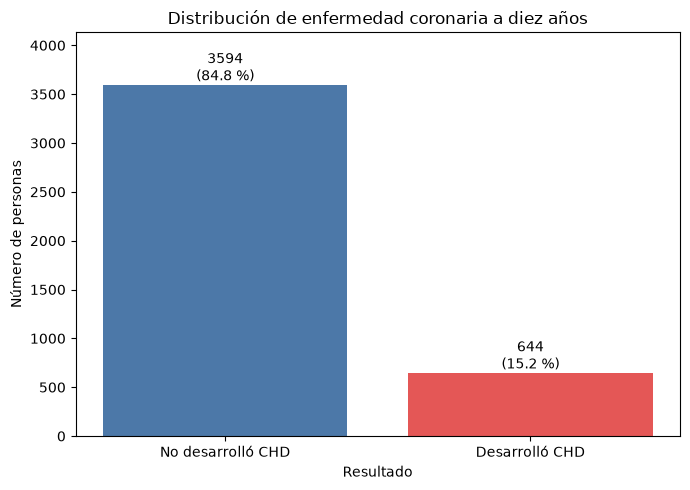

In [8]:
# Frecuencias de la variable de respuesta
conteo_chd = (
    df_analisis["TenYearCHD"]
    .value_counts()
    .sort_index()
)

# Porcentaje de cada categoría
porcentaje_chd = (
    conteo_chd / conteo_chd.sum() * 100
)

etiquetas = [
    "No desarrolló CHD",
    "Desarrolló CHD"
]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(
    etiquetas,
    conteo_chd.values,
    color=["#4C78A8", "#E45756"]
)

# Escribir frecuencia y porcentaje sobre cada barra
for barra, frecuencia, porcentaje in zip(
    barras,
    conteo_chd.values,
    porcentaje_chd.values
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{frecuencia}\n({porcentaje:.1f} %)",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Distribución de enfermedad coronaria a diez años"
)
ax.set_xlabel("Resultado")
ax.set_ylabel("Número de personas")
ax.set_ylim(0, conteo_chd.max() * 1.15)

plt.tight_layout()

# Guardar el gráfico para utilizarlo en el informe
fig.savefig(
    "fase-1/formativa-1/figuras/distribucion_chd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Interpretación.** La mayoría de las personas no desarrolló enfermedad coronaria durante los diez años de seguimiento. El grupo sin enfermedad representa el 84,80 % de la muestra, mientras que el grupo que sí la desarrolló representa el 15,20 %. Esta diferencia evidencia un desequilibrio entre los tamaños de los grupos, que deberá considerarse al interpretar las comparaciones posteriores.

### 5.2 Distribución de las variables cuantitativas

Los histogramas permiten observar la forma de las distribuciones, su concentración, asimetría y posibles valores extremos. Cada variable se presenta con su propia escala y unidad de medida.

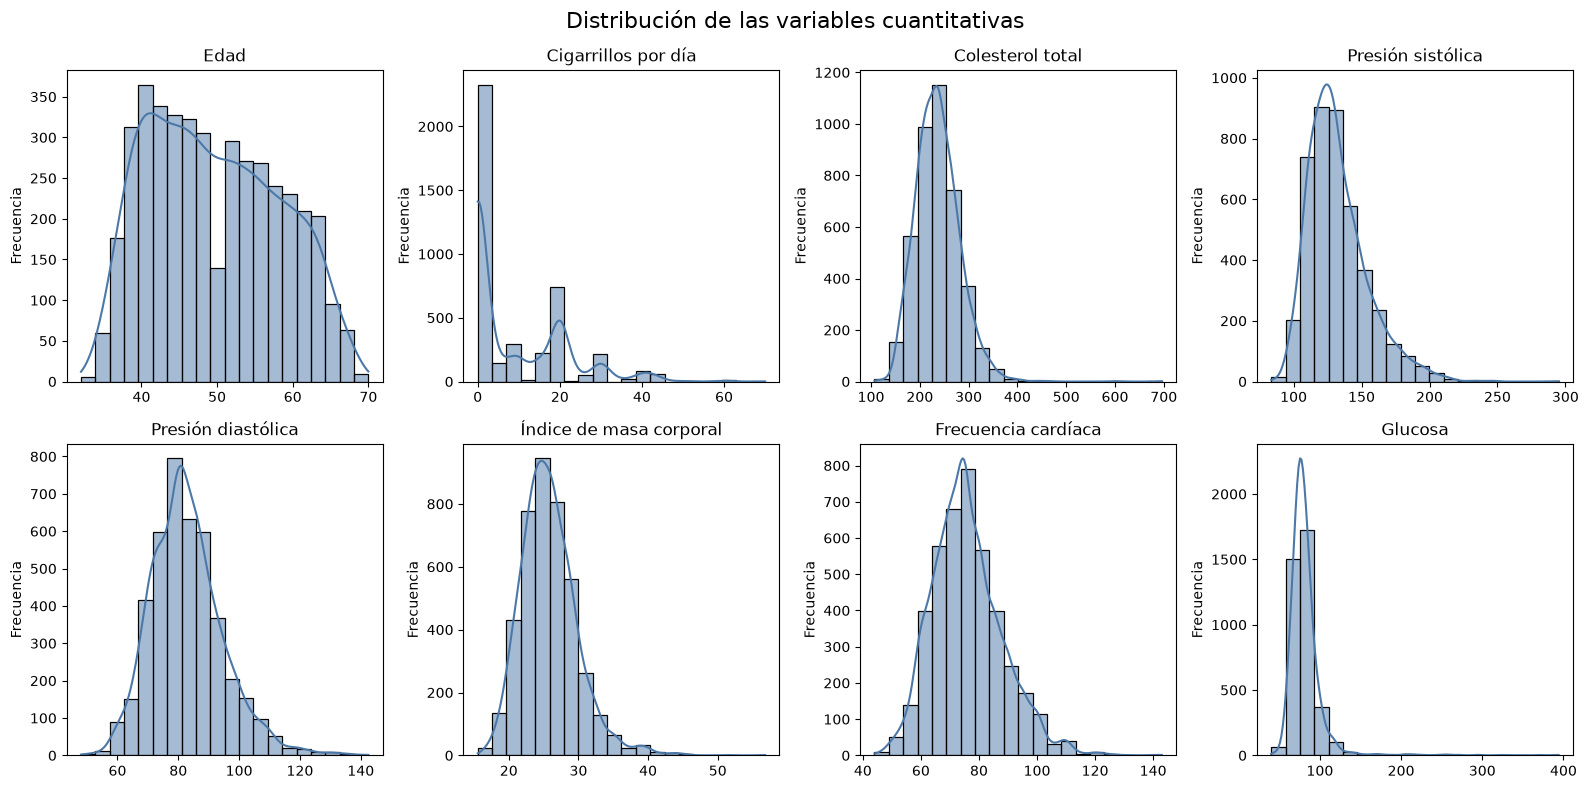

In [9]:
titulos_cuantitativas = {
    "age": "Edad",
    "cigsPerDay": "Cigarrillos por día",
    "totChol": "Colesterol total",
    "sysBP": "Presión sistólica",
    "diaBP": "Presión diastólica",
    "BMI": "Índice de masa corporal",
    "heartRate": "Frecuencia cardíaca",
    "glucose": "Glucosa"
}

fig, ejes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

for variable, eje in zip(
    variables_cuantitativas,
    ejes.flatten()
):
    sns.histplot(
        data=df_analisis,
        x=variable,
        bins=20,
        kde=True,
        color="#4C78A8",
        ax=eje
    )

    eje.set_title(titulos_cuantitativas[variable])
    eje.set_xlabel("")
    eje.set_ylabel("Frecuencia")

fig.suptitle(
    "Distribución de las variables cuantitativas",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    "fase-1/formativa-1/figuras/distribuciones_cuantitativas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Interpretación.** Las variables cuantitativas no presentan la misma forma de distribución. `cigsPerDay` concentra una cantidad importante de observaciones en cero, debido a las personas que no fuman, y presenta una extensión hacia valores más altos.

Las variables clínicas muestran distintos grados de asimetría. En particular, `glucose` presenta una concentración en valores bajos y medios junto con algunos valores considerablemente elevados. La presión sistólica, el colesterol y el índice de masa corporal también presentan observaciones alejadas de la zona central.

Debido a estas características, la media y la desviación estándar se interpretarán junto con la mediana y el rango intercuartílico, que son menos sensibles a valores extremos.

### 5.3 Comparación de variables cuantitativas según enfermedad coronaria

Se comparan algunas características demográficas y clínicas entre las personas que desarrollaron enfermedad coronaria y aquellas que no la desarrollaron. Los diagramas de caja permiten observar diferencias preliminares en la mediana, la dispersión y los valores potencialmente atípicos.

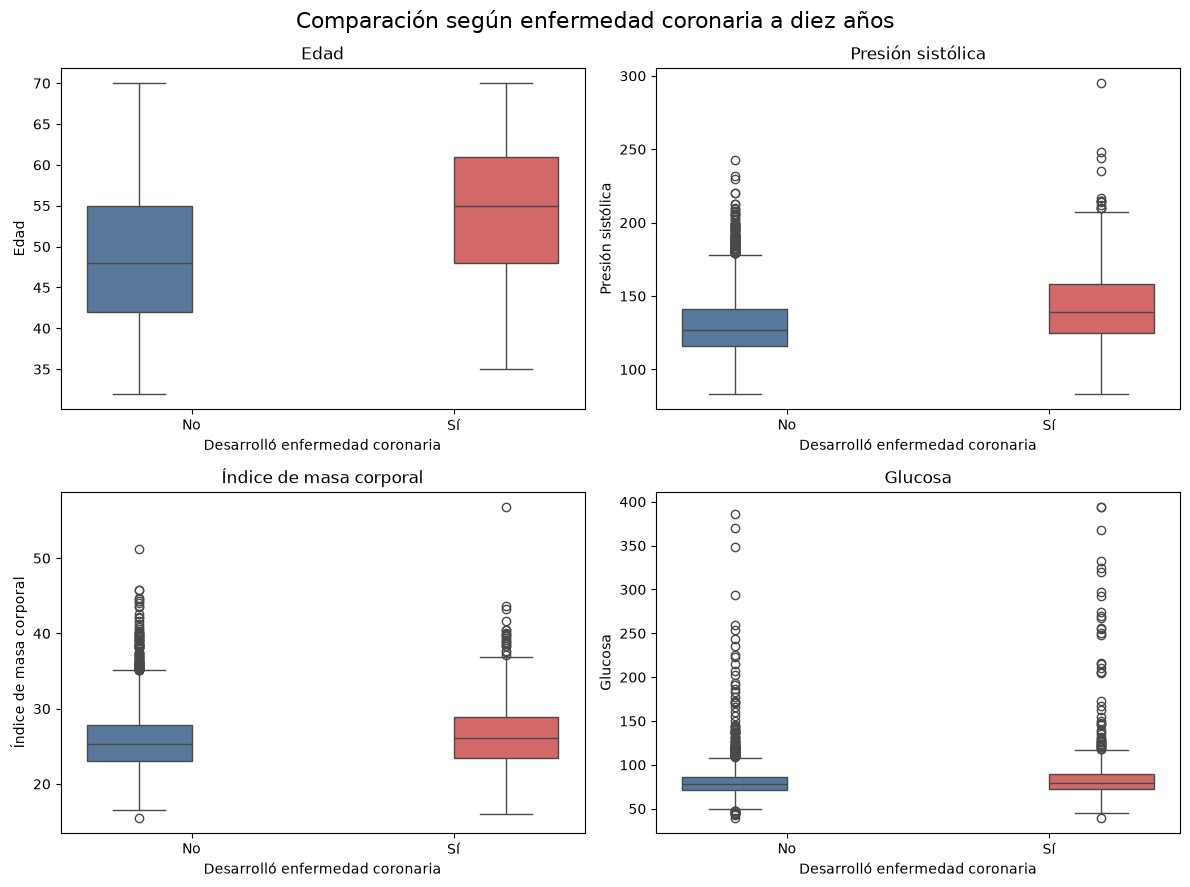

In [10]:
variables_comparacion = [
    "age",
    "sysBP",
    "BMI",
    "glucose"
]

titulos_comparacion = {
    "age": "Edad",
    "sysBP": "Presión sistólica",
    "BMI": "Índice de masa corporal",
    "glucose": "Glucosa"
}

fig, ejes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

for variable, eje in zip(
    variables_comparacion,
    ejes.flatten()
):
    sns.boxplot(
        data=df_analisis,
        x="TenYearCHD",
        y=variable,
        hue="TenYearCHD",
        palette={
            0: "#4C78A8",
            1: "#E45756"
        },
        legend=False,
        ax=eje
    )

    eje.set_title(titulos_comparacion[variable])
    eje.set_xlabel("Desarrolló enfermedad coronaria")
    eje.set_ylabel(titulos_comparacion[variable])
    eje.set_xticks(
        [0, 1],
        labels=["No", "Sí"]
    )

fig.suptitle(
    "Comparación según enfermedad coronaria a diez años",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    "fase-1/formativa-1/figuras/comparacion_variables_chd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Interpretación.** Los diagramas de caja sugieren que las personas que desarrollaron enfermedad coronaria presentan una edad y una presión sistólica generalmente mayores que quienes no la desarrollaron.

Para el índice de masa corporal se observa un solapamiento considerable entre ambos grupos, por lo que la diferencia visual parece menos marcada. La glucosa presenta valores elevados y potencialmente atípicos en ambos grupos, aunque su distribución parece desplazarse hacia valores mayores entre quienes desarrollaron la enfermedad.

Estas observaciones corresponden a diferencias descriptivas. Los gráficos no permiten concluir por sí solos que las diferencias sean estadísticamente significativas ni que exista una relación causal.

### 5.4 Enfermedad coronaria según antecedente de hipertensión

Se compara el porcentaje de personas que desarrolló enfermedad coronaria entre quienes presentan y quienes no presentan antecedentes de hipertensión.

,grupo,total_personas,casos_chd,porcentaje_chd
0,Sin hipertensión,2922,319,10.92
1,Con hipertensión,1316,325,24.70


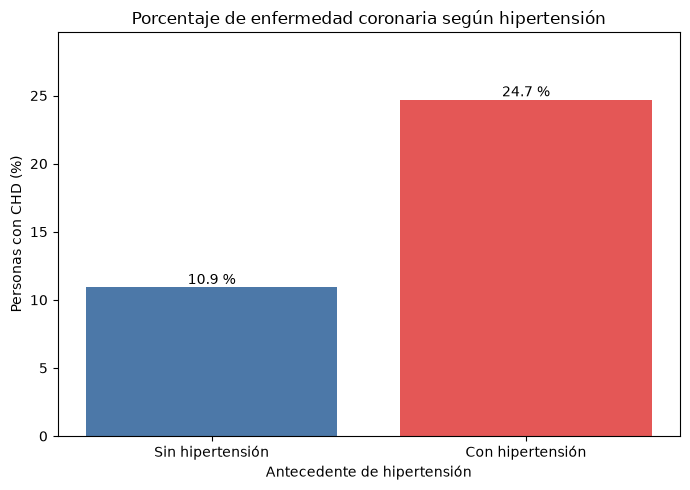

In [11]:
# Resumir enfermedad coronaria dentro de cada grupo de hipertensión
resumen_hipertension = (
    df
    .groupby("prevalentHyp")["TenYearCHD"]
    .agg(
        total_personas="count",
        casos_chd="sum",
        proporcion_chd="mean"
    )
    .reset_index()
)

resumen_hipertension["porcentaje_chd"] = (
    resumen_hipertension["proporcion_chd"] * 100
).round(2)

resumen_hipertension["grupo"] = resumen_hipertension[
    "prevalentHyp"
].map({
    0: "Sin hipertensión",
    1: "Con hipertensión"
})

display(
    resumen_hipertension[
        [
            "grupo",
            "total_personas",
            "casos_chd",
            "porcentaje_chd"
        ]
    ]
)

# Crear el gráfico
fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(
    resumen_hipertension["grupo"],
    resumen_hipertension["porcentaje_chd"],
    color=["#4C78A8", "#E45756"]
)

for barra, porcentaje in zip(
    barras,
    resumen_hipertension["porcentaje_chd"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{porcentaje:.1f} %",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Porcentaje de enfermedad coronaria según hipertensión"
)
ax.set_xlabel("Antecedente de hipertensión")
ax.set_ylabel("Personas con CHD (%)")
ax.set_ylim(
    0,
    resumen_hipertension["porcentaje_chd"].max() * 1.20
)

plt.tight_layout()

fig.savefig(
    "fase-1/formativa-1/figuras/chd_segun_hipertension.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Interpretación.** El porcentaje de personas que desarrolló enfermedad coronaria es mayor en el grupo con antecedentes de hipertensión que en el grupo sin hipertensión.

Esta diferencia sugiere una relación preliminar entre ambas variables dentro de la muestra analizada. Sin embargo, el gráfico presenta una comparación descriptiva y no permite concluir por sí solo que la hipertensión cause la enfermedad coronaria ni que la diferencia pueda generalizarse a toda la población.

Posteriormente se aplicará una prueba de independencia para evaluar si existe evidencia estadística de asociación entre el antecedente de hipertensión y el desarrollo de enfermedad coronaria.

## 6. Estimación puntual e intervalo de confianza

### 6.1 Proporción de enfermedad coronaria

La proporción observada de personas que desarrolló enfermedad coronaria constituye una estimación puntual. Para expresar la incertidumbre asociada a esta estimación se calculará un intervalo de confianza del 95 % mediante el método de Wilson.

In [12]:
from statsmodels.stats.proportion import proportion_confint

# Número total de observaciones y casos de enfermedad coronaria
n_total = df["TenYearCHD"].notna().sum()
casos_chd = int(df["TenYearCHD"].sum())

# Estimación puntual
proporcion_chd = casos_chd / n_total

# Intervalo de confianza del 95 % mediante el método de Wilson
limite_inferior, limite_superior = proportion_confint(
    count=casos_chd,
    nobs=n_total,
    alpha=0.05,
    method="wilson"
)

resultado_ic_proporcion = pd.DataFrame({
    "estimacion": ["Proporción de CHD"],
    "n": [n_total],
    "casos": [casos_chd],
    "proporcion": [proporcion_chd],
    "limite_inferior_95": [limite_inferior],
    "limite_superior_95": [limite_superior]
})

display(
    resultado_ic_proporcion.style.format({
        "proporcion": "{:.4f}",
        "limite_inferior_95": "{:.4f}",
        "limite_superior_95": "{:.4f}"
    })
)

print(
    f"Estimación puntual: {proporcion_chd * 100:.2f} %"
)

print(
    "Intervalo de confianza del 95 %: "
    f"[{limite_inferior * 100:.2f} %, "
    f"{limite_superior * 100:.2f} %]"
)

,estimacion,n,casos,proporcion,limite_inferior_95,limite_superior_95
0,Proporción de CHD,4238,644,0.1520,0.1415,0.1631


Estimación puntual: 15.20 %
Intervalo de confianza del 95 %: [14.15 %, 16.31 %]


#### Interpretación

En la muestra analizada, 644 de las 4238 personas desarrollaron enfermedad coronaria durante los diez años de seguimiento. Esto corresponde a una proporción observada de aproximadamente **15,20 %**.

El intervalo de confianza del 95 % indica un rango plausible para la proporción poblacional de personas con enfermedad coronaria, considerando el procedimiento de muestreo y los supuestos del análisis.

Este resultado no significa que cada persona tenga un 15,20 % de probabilidad individual de desarrollar la enfermedad. Tampoco permite generalizar automáticamente los resultados a toda la población, porque la representatividad depende del origen y del diseño del estudio Framingham.

### 6.2 Presión arterial sistólica media

La media observada de la presión arterial sistólica (`sysBP`) se utiliza como estimación puntual de la media poblacional. Para cuantificar su precisión se construye un intervalo de confianza del 95 % mediante la distribución *t* de Student.

Este método se utiliza porque la desviación estándar poblacional es desconocida y debe estimarse a partir de la muestra. La variable no presenta valores ausentes, por lo que se utilizan las 4.238 observaciones disponibles.


In [13]:
presion_sistolica = df["sysBP"].dropna()

n_sysbp = len(presion_sistolica)
media_sysbp = presion_sistolica.mean()
desviacion_sysbp = presion_sistolica.std(ddof=1)
error_estandar_sysbp = stats.sem(presion_sistolica)

limite_inferior_sysbp, limite_superior_sysbp = stats.t.interval(
    confidence=0.95,
    df=n_sysbp - 1,
    loc=media_sysbp,
    scale=error_estandar_sysbp
)

resultado_ic_sysbp = pd.DataFrame({
    "estimacion": ["Media de presión sistólica"],
    "n": [n_sysbp],
    "media": [media_sysbp],
    "desviacion_estandar": [desviacion_sysbp],
    "error_estandar": [error_estandar_sysbp],
    "limite_inferior_95": [limite_inferior_sysbp],
    "limite_superior_95": [limite_superior_sysbp]
})

display(resultado_ic_sysbp.round(2))

print(f"Estimación puntual: {media_sysbp:.2f} mmHg")
print(
    "Intervalo de confianza del 95 %: "
    f"[{limite_inferior_sysbp:.2f}, "
    f"{limite_superior_sysbp:.2f}] mmHg"
)


,estimacion,n,media,desviacion_estandar,error_estandar,limite_inferior_95,limite_superior_95
0,Media de presión sistólica,4238,132.35,22.04,0.34,131.69,133.02


Estimación puntual: 132.35 mmHg
Intervalo de confianza del 95 %: [131.69, 133.02] mmHg


#### Interpretación

La presión arterial sistólica media de la muestra es **132.35 mmHg**. El intervalo de confianza del 95 % se extiende desde **131.69 hasta 133.02 mmHg**.

Este intervalo entrega un rango plausible para la presión sistólica media de la población de referencia, bajo los supuestos del procedimiento y del diseño muestral. Su amplitud reducida refleja la precisión asociada al tamaño de la muestra, pero no corrige posibles problemas de representatividad o medición.

El intervalo estima una media poblacional; no significa que el 95 % de las personas tenga una presión comprendida dentro de ese rango.


## 7. Prueba de hipótesis básica

### Comparación de la presión sistólica según enfermedad coronaria

Se utiliza una prueba *t* de Welch para comparar la presión arterial sistólica media (`sysBP`) entre las personas que desarrollaron enfermedad coronaria y aquellas que no la desarrollaron. Esta prueba es adecuada para comparar las medias de dos grupos independientes y no exige igualdad de varianzas.

- $H_0$: la presión sistólica media es igual en ambos grupos.
- $H_1$: la presión sistólica media es diferente entre ambos grupos.
- Nivel de significancia: $\alpha=0{,}05$.

Se asume que las observaciones corresponden a personas independientes. Los diagramas de caja muestran valores extremos, pero ambos grupos tienen tamaños muestrales grandes. Se utiliza la versión de Welch para no imponer el supuesto de varianzas iguales.


In [14]:
sysbp_sin_chd = df.loc[
    df["TenYearCHD"] == 0,
    "sysBP"
].dropna()

sysbp_con_chd = df.loc[
    df["TenYearCHD"] == 1,
    "sysBP"
].dropna()

estadistico_t, valor_p_t = stats.ttest_ind(
    sysbp_con_chd,
    sysbp_sin_chd,
    equal_var=False
)

n_con = len(sysbp_con_chd)
n_sin = len(sysbp_sin_chd)
media_con = sysbp_con_chd.mean()
media_sin = sysbp_sin_chd.mean()
varianza_con = sysbp_con_chd.var(ddof=1)
varianza_sin = sysbp_sin_chd.var(ddof=1)

diferencia_medias = media_con - media_sin
error_diferencia = np.sqrt(
    varianza_con / n_con + varianza_sin / n_sin
)

grados_libertad_welch = (
    (varianza_con / n_con + varianza_sin / n_sin) ** 2
    / (
        (varianza_con / n_con) ** 2 / (n_con - 1)
        + (varianza_sin / n_sin) ** 2 / (n_sin - 1)
    )
)

margen_error = (
    stats.t.ppf(0.975, grados_libertad_welch)
    * error_diferencia
)

limite_inferior_diferencia = diferencia_medias - margen_error
limite_superior_diferencia = diferencia_medias + margen_error

desviacion_combinada = np.sqrt(
    (
        (n_con - 1) * varianza_con
        + (n_sin - 1) * varianza_sin
    )
    / (n_con + n_sin - 2)
)

d_cohen = diferencia_medias / desviacion_combinada

resumen_prueba_t = pd.DataFrame({
    "grupo": ["Sin CHD", "Con CHD"],
    "n": [n_sin, n_con],
    "media_sysBP": [media_sin, media_con],
    "desviacion_estandar": [
        sysbp_sin_chd.std(ddof=1),
        sysbp_con_chd.std(ddof=1)
    ]
})

display(resumen_prueba_t.round(2))

print(
    "Diferencia de medias (con CHD - sin CHD): "
    f"{diferencia_medias:.2f} mmHg"
)
print(
    "IC del 95 % para la diferencia: "
    f"[{limite_inferior_diferencia:.2f}, "
    f"{limite_superior_diferencia:.2f}] mmHg"
)
print(f"Estadístico t de Welch: {estadistico_t:.3f}")
print(f"Valor p: {valor_p_t:.4g}")
print(f"d de Cohen: {d_cohen:.3f}")
print(
    "Decisión:",
    "se rechaza H0" if valor_p_t < 0.05 else "no se rechaza H0"
)


,grupo,n,media_sysBP,desviacion_estandar
0,Sin CHD,3594,130.33,20.46
1,Con CHD,644,143.62,26.69


Diferencia de medias (con CHD - sin CHD): 13.29 mmHg
IC del 95 % para la diferencia: [11.11, 15.46] mmHg
Estadístico t de Welch: 12.015
Valor p: 1.21e-30
d de Cohen: 0.617
Decisión: se rechaza H0


#### Interpretación

La presión sistólica media fue de **130.33 mmHg** entre quienes no desarrollaron enfermedad coronaria y de **143.62 mmHg** entre quienes sí la desarrollaron. La diferencia estimada fue de **13.29 mmHg**, con un intervalo de confianza del 95 % entre **11.11 y 15.46 mmHg**.

El valor *p* obtenido fue menor que $0{,}05$; por lo tanto, se rechaza la hipótesis nula y se concluye que existe evidencia estadística de una diferencia en la presión sistólica media entre ambos grupos. El tamaño del efecto, medido mediante $d$ de Cohen, fue **0.617**, lo que permite complementar la significancia estadística con la magnitud estandarizada de la diferencia.

Este resultado muestra una asociación y no demuestra que una presión sistólica elevada cause por sí sola la enfermedad coronaria. No se están controlando simultáneamente otros factores como edad, sexo, tabaquismo o diabetes.


## 8. Síntesis de resultados

- El conjunto de datos seleccionado corresponde a un contexto real de salud cardiovascular y contiene 4.238 observaciones y 16 variables.
- Se identificaron variables cualitativas nominales, una variable cualitativa ordinal y variables cuantitativas discretas y continuas.
- No se detectaron filas duplicadas. Siete variables presentan valores ausentes; `glucose` concentra el mayor porcentaje, con 9,16 %.
- El 15,20 % de las personas desarrolló enfermedad coronaria durante los diez años de seguimiento. El intervalo de confianza de Wilson del 95 % para esta proporción es 14,15 %–16,31 %.
- La presión sistólica media es 132.35 mmHg y su intervalo de confianza del 95 % se encuentra entre 131.69 y 133.02 mmHg.
- Los análisis descriptivos sugieren que quienes desarrollaron enfermedad coronaria presentan mayor edad y presión sistólica.
- La presión sistólica media fue 130.33 mmHg en el grupo sin enfermedad coronaria y 143.62 mmHg en el grupo con enfermedad. La prueba t de Welch aporta evidencia estadística de una diferencia entre ambas medias.

## 9. Limitaciones

Este es un análisis observacional, por lo que permite identificar asociaciones, pero no establecer relaciones causales. Los resultados tampoco deben generalizarse automáticamente a cualquier población, ya que su representatividad depende del diseño y del origen del estudio Framingham.

Los datos ausentes se conservaron y cada cálculo utilizó los registros disponibles. Esta decisión evita introducir valores artificiales, aunque podría existir sesgo si la ausencia de información no fuera aleatoria. Además, los análisis realizados no controlan simultáneamente posibles factores de confusión.

## 10. Conclusiones

El trabajo permitió definir un problema de análisis, documentar y clasificar las variables y describir relaciones preliminares relevantes. La edad, la presión arterial y el antecedente de hipertensión aparecen como características de interés para comprender las diferencias entre las personas que desarrollaron y las que no desarrollaron enfermedad coronaria.

La inferencia realizada cuantifica la incertidumbre de la proporción observada y respalda estadísticamente la diferencia de presión sistólica media entre los dos grupos. Estos hallazgos constituyen una base inicial para continuar el proyecto, pero deben interpretarse como evidencia preliminar y no causal.

## Referencias

- Dileep, A. *Logistic Regression to Predict Heart Disease*. Kaggle. https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression
- National Heart, Lung, and Blood Institute. *Teaching Datasets*. https://biolincc.nhlbi.nih.gov/teaching/
